[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/kinhteluong/blob/main/KTL%20T%C3%A0i%20ch%C3%ADnh/Module_7/B3_Nhan_qua_Granger_va_mang.ipynb)

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

!pip install -q yfinance

print("Bài này không cần tải dữ liệu.")

## KINH TẾ LƯỢNG TÀI CHÍNH
MODULE 7 | BÀI 3

---

# **NHÂN QUẢ GRANGER VÀ LÝ THUYẾT MẠNG LƯỚI**

|  |  |
|:---|:---|
|**Thời gian đọc** |60 phút|
|**Kiến thức nền** |OLS, ma trận hiệp phương sai, mô hình VAR, lý thuyết mạng lưới cơ bản, Python cơ bản|
|**Từ khóa** |Liên hệ (association), nhân quả, nhân quả Granger|
|  |  |

## **1. Giới thiệu**
Ở bài trước, ta thường bàn về việc một biến ảnh hưởng đến biến khác trong mạng lưới như thế nào. Trong bài này, ta sẽ đi thêm một bước và bàn về các loại quan hệ khác nhau giữa các biến. Trước tiên ta giới thiệu khái niệm liên hệ (association) giữa các biến và các đặc điểm của nó. Tiếp theo, ta giải thích ngắn gọn về nhân quả. Sau đó ta giới thiệu nhân quả Granger, giải thích các giả định và hạn chế của nó. Ta cũng đưa ra một số ví dụ ứng dụng nhân quả Granger. Cuối cùng, ta chỉ cách kết hợp nhân quả Granger với mạng lưới để phân tích quan hệ giữa các chuỗi thời gian.

## **2. Liên hệ và nhân quả**
### **2.1. Hiểu về liên hệ (association)**
**Liên hệ (Association)** hay **tương quan (correlation)** dùng để mô tả quan hệ hay mẫu hình thống kê của hai chuỗi thời gian (Nicolae và cộng sự, 2022). Hệ số tương quan của hai chuỗi thời gian cho ta biết độ mạnh của liên hệ tuyến tính giữa hai chuỗi.

Một số tính chất quan trọng của liên hệ như sau:
1. Quan hệ có tính đối xứng, nghĩa là nếu X có liên hệ với Y thì Y cũng có liên hệ với X
2. Liên hệ không cho biết một biến có ảnh hưởng hay có kết nối trực tiếp đến biến kia không. Ta cũng gọi là không có hướng
3. Liên hệ có thể tồn tại ngay cả khi hai biến không có kết nối nhân quả trực tiếp
4. Liên hệ có thể đo bằng hệ số tương quan

Nếu hệ số tương quan cho thấy hai chuỗi thời gian có liên hệ (tương quan) cao, câu hỏi tiếp theo của ta thường là: chuỗi này có gây ra chuỗi kia không? Có hai kịch bản nhân quả có thể xảy ra:

1. Nhân quả trực tiếp: thay đổi ở biến X gây ra thay đổi ở biến Y (hoặc ngược lại)
2. Phản ứng chung: biến X và biến Y cùng chịu ảnh hưởng của biến Z

Ta có thể dùng đồ thị mạng đã học ở bài trước để minh họa hai kịch bản này.

**Hình 1. Đồ thị mạng cho các loại nhân quả của liên hệ**

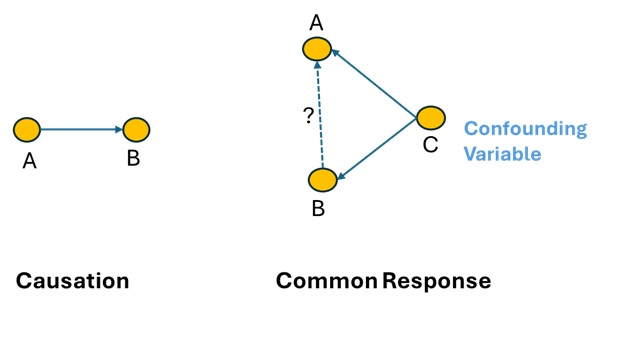

Từ Hình 1, ta thấy tình huống Nhân quả trực tiếp bên trái là quan hệ nhân quả đơn giản nhất. Tình huống Phản ứng chung bên phải giống trường hợp phức tạp có biến gây nhiễu C ở bài trước. Khi một biến gây nhiễu không được đưa vào mô hình, kết quả mô hình sẽ tạo ra một liên hệ giả. Để loại bỏ liên hệ giả (sai) giữa A và B, nhà nghiên cứu nên xác định và kiểm soát các biến gây nhiễu.

### **2.2. Hiểu về nhân quả**
**Nhân quả (Causality)** nghĩa là một biến ảnh hưởng trực tiếp hoặc tạo ra thay đổi ở một biến khác (Hansen, 2014). Suy luận nhân quả (Causal Inference) là phương pháp phân tích quan hệ nguyên nhân-kết quả thực sự giữa các biến.

Một biến $x_{1}$ được coi là có ảnh hưởng nhân quả lên biến kết quả $y$ nếu thay đổi $x_{1}$ dẫn đến thay đổi $y$, trong khi giả định mọi biến khác giữ cố định. Mô hình đầy đủ cho kết quả có thể viết là:

$$y = h(x_1, x_2, u)$$

trong đó $x_{1}$ và $x_{2}$ là các đầu vào quan sát được,

$u$ là thành phần ngẫu nhiên không đo được,

$h$ mô tả quan hệ hàm giữa các yếu tố này.

Tác động nhân quả của $x_1$ được định nghĩa là tốc độ thay đổi của $y$ theo $x_1$, trong khi giữ $x_2$ và $u$ không đổi:

$$C(x_1, x_2, u) = \nabla_1 h(x_1, x_2, u)$$

trong đó $\nabla_1$ là đạo hàm riêng theo $x_1$.

Các tính chất chính của nhân quả:

1. Nhân quả là quan hệ bất đối xứng, nghĩa là nếu X gây ra Y thì không có nghĩa Y nhất thiết gây ra X.
2. Nhân quả cho biết biến nào ảnh hưởng biến kia, nên có hướng.
3. Nhân quả có tính tuần tự, nghĩa là nguyên nhân đi trước kết quả
4. Có một cơ chế khiến ảnh hưởng xảy ra


### **3. Nhân quả Granger**
#### **3.1. Giới thiệu**
Ở mục trước, ta đã bàn về liên hệ và nhân quả. Trong mục này, ta giới thiệu một phương pháp liên quan khác để phân tích quan hệ giữa hai chuỗi thời gian: Nhân quả Granger. **Nhân quả Granger (Granger Causality)** là khung do Granger (1969) giới thiệu để đánh giá liệu các giá trị quá khứ của một chuỗi thời gian có dự báo được chuỗi thời gian kia không. Ví dụ, nhân quả Granger được dùng để kiểm tra các giá trị lịch sử của $x_t$ có dự báo được $y_t$ không. Nếu có, ta nói $x$ Granger gây ra $y$. Nhân quả Granger tận dụng đặc điểm chỉ mục thời gian, tức các giá trị trong chuỗi thời gian có thứ tự, để nghiên cứu quan hệ nguyên nhân-kết quả cho chuỗi thời gian.

Một điều ta cần cẩn thận là ngay cả khi $x$ Granger gây ra $y$, điều này không nhất thiết nghĩa là $x$ trực tiếp gây ra $y$. Nhân quả Granger khác với nhân quả ta bàn ở mục trước. Nhân quả Granger tập trung nhiều hơn vào việc dùng lịch sử của một biến để dự báo biến khác chứ không phải phân tích nguyên nhân-kết quả thực sự.

Các nhà nghiên cứu đã dùng nhân quả Granger để tìm các tương tác giữa các biến trong tài chính và kinh tế vĩ mô. Ví dụ, Billio và cộng sự (2012) dùng nhân quả Granger để hiểu mức độ liên kết và rủi ro hệ thống của các tổ chức tài chính. Tuy nhiên, nhân quả Granger có những hạn chế trong việc cung cấp thông tin nhân quả giữa các chuỗi thời gian. Ta sẽ bàn các hạn chế này ở phần sau của mục này. Trước tiên, hãy mô tả chính thức nhân quả Granger.
#### **3.2. Khái niệm nhân quả Granger**
Ta có hai chuỗi thời gian **dừng** $x_t$ và $y_t$. Với hai chuỗi này, ta có thể định nghĩa hai tập thông tin sau:

$$\mathcal{H}_{1,t}=(y_{t},y_{t-1},y_{t-2},...)$$

$$\mathcal{H}_{2,t}=(y_{t},x_{t},y_{t-1},x_{t-1},y_{t-2},x_{t-2},...)$$

trong đó tập thông tin $\mathcal{H}_{1,t}$ chỉ gồm thông tin từ $y_t$ và tập thông tin $\mathcal{H}_{2,t}$ gồm thông tin từ cả $y_t$ và $x_t$.

Ta nói $x$ 'Granger gây ra' $y$ nếu

$$var[y_t - \mathcal{P}(y_t|\mathcal{H_{2,t-1}})]\lt var[y_t - \mathcal{P}(y_t|\mathcal{H_{1,t-1}})]\quad\quad\quad\quad(1)$$

trong đó $\mathcal{P}(y_t|\mathcal{H_{2,t-1}})$ là dự báo tối ưu của $y_t$ khi biết tập thông tin $\mathcal{H_{2,t-1}}$ và $\mathcal{P}(y_t|\mathcal{H_{1,t-1}})$ là dự báo tối ưu của $y_t$ khi biết tập thông tin $\mathcal{H_{1,t-1}}$

Phương trình $(1)$ nói rằng khi phương sai của sai số dự báo $y_t$ với tập thông tin $\mathcal{H_{2,t-1}}$ nhỏ hơn phương sai của sai số dự báo $y_t$ với tập thông tin $\mathcal{H_{1,t-1}}$, thì chuỗi thời gian $x$ Granger gây ra $y$. Nghĩa là việc thêm các giá trị quá khứ của $x_t$ vào mô hình cải thiện dự báo $y_t$ và giảm phương sai của sai số dự báo.

Dựa trên khung trên, ta thực hiện kiểm định nhân quả Granger thực tế thế nào? Ta có thể bắt đầu bằng việc viết hai mô hình hồi quy OLS sau:

(mô hình rút gọn)

$$y_t=\alpha_0+\alpha_1y_{t-1}+\alpha_2y_{t-2}...+\alpha_py_{t-p}+\epsilon_{t(\mathcal{H}_1)}\quad\quad\quad\quad\quad\quad\quad\quad\quad\quad\quad\quad\quad\quad\quad(2)$$

(mô hình đầy đủ)

$$y_t=\alpha_0+\alpha_1y_{t-1}+\alpha_2y_{t-2}...+\alpha_py_{t-p}+\beta_1x_{t-1}+\beta_2x_{t-2}...+\beta_px_{t-p}+\epsilon_{t(\mathcal{H}_2)}\quad\quad\quad(3)$$

trong đó  $\alpha_i$  là hệ số của  $y_i$  và  $\beta_j$  là hệ số của  $x_j$  với  $i,j\in[1,2,...,p]$

$\epsilon_{t(\mathcal{H_{1}})}$ là nhiễu trắng của mô hình rút gọn
$\epsilon_{t(\mathcal{H_{2}})}$  là nhiễu trắng của mô hình đầy đủ

Phương trình  $(2)$  là mô hình chỉ dùng các giá trị quá khứ của $y$ để dự báo  $y_t$  còn phương trình  $(3)$  là mô hình dùng không chỉ các giá trị quá khứ của  $y$  mà cả các giá trị quá khứ của  $x$  để dự báo  $y_t$ . Phương trình  $(2)$  dùng tập thông tin  $\mathcal{H_{1}}$  nên mô hình này là mô hình rút gọn chỉ dùng một phần thông tin. Phương trình  $(3)$  dùng tập thông tin  $\mathcal{H_{2}}$  nên mô hình này là mô hình đầy đủ dùng toàn bộ thông tin.
Để kiểm tra  $x$  có Granger gây ra  $y$  không, ta viết kiểm định giả thuyết sau:

$$H_0:\beta_1=\beta_2=...=\beta_p=0$$

$$H1:\text{ít nhất một }\beta\neq0 $$

Để kiểm định giả thuyết trên, ta dùng kiểm định $F$. Thống kê kiểm định như sau:

$$F=\frac{(RSS_{reduced}-RSS_{full})/(r-s)}{(RSS_{full})/(T-r)}$$

trong đó  $RSS$ là tổng bình phương phần dư của mô hình hồi quy

$r$  là số tham số trong mô hình đầy đủ

$s$ là số tham số trong mô hình rút gọn

$T$ là số quan sát

Nếu giá trị $p$ của kiểm định $F$ nhỏ hơn 5% khi mức ý nghĩa đặt ở 5%, ta bác bỏ giả thuyết không ($H_0$) và nói  $x$  Granger gây ra $y$. Sau đó ta đổi vai trò $x$ và $y$ để lặp lại quy trình trên, kiểm tra $y$ có Granger gây ra $x$ không.

#### **3.3. Mô hình tự hồi quy vectơ (VAR) và nhân quả Granger**
Ở mục trước, ta mô tả chi tiết quy trình kiểm tra $x$ có Granger gây ra $y$ không rồi dùng cùng quy trình đó để kiểm tra $y$ có Granger gây ra $x$ không. Nhiều khi, ta có thể trình bày hai kiểm định nhân quả Granger vừa rồi trong khung VAR(p) hai biến. Trước tiên hãy viết một mô hình VAR cho $x$ và $y$ với độ trễ $p$.

$$x_t=\phi_0+\phi_1x_{t-1}+\phi_2x_{t-2}...+\phi_px_{t-p}+\theta_1y_{t-1}+\theta_2y_{t-2}...+\theta_py_{t-p}+\varepsilon_{t}\quad\quad\quad(4)$$

$$y_t=\alpha_0+\alpha_1y_{t-1}+\alpha_2y_{t-2}...+\alpha_py_{t-p}+\beta_1x_{t-1}+\beta_2x_{t-2}...+\beta_px_{t-p}+\epsilon_{t}\quad\quad\quad(5)$$

Sau đó ta ước lượng mô hình VAR($p$) này. Khi có ước lượng hệ số của mô hình, ta có thể tiến hành kiểm định nhân quả Granger. Ví dụ, nếu muốn kiểm tra $x$ có Granger gây ra $y$ không, nó tương đương kiểm định $H_0: \beta_1=\beta_2=...=\beta_p$. Nếu muốn kiểm tra $y$ có Granger gây ra $x$ không, nó tương đương kiểm định $H_0:\theta_1=\theta_2=...=\theta_p=0$.

Một lý do khác để dùng khung VAR($p$) cho kiểm định nhân quả Granger là việc chọn số độ trễ $p$. Điều này dẫn đến chủ đề tiếp theo: các giả định của nhân quả Granger.
#### **3.4. Giả định và hạn chế của nhân quả Granger**
Bây giờ bạn đã thấy cách thiết lập kiểm định nhân quả Granger cho hai chuỗi thời gian. Bạn cũng có thể đã thấy một vài giả định ta dùng khi mô tả quy trình. Hãy tóm tắt các giả định chính ở đây.

**Tính dừng**

Hai chuỗi thời gian cần dừng trước khi áp dụng kiểm định nhân quả Granger. Ta có thể dùng kiểm định Dickey-Fuller mở rộng (ADF) để kiểm tra tính dừng. Nếu chuỗi nào không dừng, ta có thể áp dụng các phương pháp đã học ở các bài trước để biến đổi chuỗi.

**Tuyến tính**

Kiểm định nhân quả Granger giả định các chuỗi thời gian có quan hệ tuyến tính.

**Chuỗi thời gian giá trị liên tục**

Các giá trị của chuỗi thời gian dùng cho kiểm định nhân quả Granger cần liên tục.

**Không có biến gây nhiễu**

Mọi biến liên quan đều được quan sát và đưa vào phân tích, và không có biến không đo được.

**Độ trễ đã biết**

Độ trễ của các quan sát quá khứ của biến phụ thuộc đã biết và đồng nhất giữa mọi biến.

Giả định phụ thuộc tuyến tính của chuỗi thời gian có thể gây hạn chế vì nhiều dữ liệu chuỗi thời gian có quan hệ phi tuyến. Giả định không có biến gây nhiễu thì phi thực tế, đặc biệt với mô hình hai biến ta đang bàn. Ta đã nói về vấn đề loại trừ biến gây nhiễu khỏi mô hình ở bài trước. Ta sẽ minh họa vấn đề này khi trình bày ví dụ kết hợp nhân quả Granger và mạng lưới. Về giả định độ trễ đã biết, ta có thể dùng hàm chọn bậc độ trễ trong mô hình VAR để quyết định độ trễ tối ưu cho kiểm định nhân quả Granger.

#### **3.5. Ví dụ kiểm định nhân quả Granger trong mô hình VAR hai biến**
Trong mục này, ta thử chạy nhân quả Granger chỉ cho hai chuỗi thời gian. Ta chọn lợi suất cổ phiếu JPMorgan và ETF công nghệ cho ví dụ này. Như đã bàn ở mục trước, ta cần kiểm tra tính dừng của hai chuỗi thời gian này trước khi tiến hành kiểm định nhân quả Granger. Ta sẽ dùng kiểm định ADF để kiểm tra tính dừng.

In [1]:
pip install networkx yfinance seaborn --upgrade

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 3.7 MB/s eta 0:00:00
  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.62
    Uninstalling yfinance-0.2.62:
      Successfully uninstalled yfinance-0.2.62

[notice] A new release of pip available: 22.3.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf
import warnings
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore")

In [3]:
# Gather stock data and factor data for 7 years

# Danh sách tài sản (cổ phiếu)
assets = ['AAPL',   # Apple
          'WMT',    # Walmart
          'AMZN',   # Amazon
          'GOOGL',  # Google
          'JPM',    # JP Morgan
          'WBD',    # Warner Brothers
          'GE']     # General Electric Co.

# Danh sách yếu tố
factors = [
    '^GSPC',   # S&P 500 (yếu tố thị trường)
    'XLF',     # Financial Select Sector SPDR Fund
    'XLK',     # Technology Select Sector SPDR Fund
    'SHY',     # ETF trái phiếu kho bạc ngắn hạn (yếu tố lãi suất)
    'DX-Y.NYB' # US Dollar index
]

# Gộp tài sản và yếu tố
tickers = assets + factors

# Tải dữ liệu
data = yf.download(tickers, start="2018-01-01", end="2024-12-31", auto_adjust=False)['Adj Close']

# Tính lợi suất
returns = data.pct_change().dropna()

# Thêm nhãn có ý nghĩa
returns.columns = [
    'Apple', 'Amazon', 'USD', 'GE', 'Google', 'JPMorgan', 'Treasury', 'Warner-Bro', 'Walmart', 'Financial', 'Technology', 'SP500'
]

[*********************100%***********************]  12 of 12 completed


In [4]:
# Chuẩn hóa dữ liệu
standardized_returns = (returns - returns.mean()) / returns.std()

In [5]:
# Thực hiện kiểm định ADF cho lợi suất cổ phiếu JPMorgan
jp_result = adfuller(returns['JPMorgan'])

print('Giá trị p của JPMorgan: %f' % jp_result[1])

p-value of JPMorgan: 0.000000


In [6]:
# Thực hiện kiểm định ADF cho ETF công nghệ
tech_result = adfuller(returns['Technology'])

print('Giá trị p của Technology: %f' % tech_result[1])

p-value of Technology: 0.000000


Từ kết quả của các kiểm định Dickey-Fuller mở rộng ở trên, cả hai chuỗi thời gian đều dừng. Tiếp theo ta dùng hàm chọn bậc độ trễ của mô hình VAR để tìm bậc độ trễ tối ưu cho kiểm định nhân quả Granger.

In [7]:
# Dùng bậc độ trễ tối ưu để chạy kiểm định nhân quả Granger
from statsmodels.tsa.api import VAR

# Tạo bộ dữ liệu để chạy mô hình VAR
gc_data = returns[["JPMorgan","Technology"]]

# Dùng select_order để tìm bậc độ trễ tối ưu
model = VAR(gc_data)
lag_order_results = model.select_order(maxlags=10)
lag_order = lag_order_results.aic # Cũng có thể dùng bic, fpe hoặc hqic
print('Bậc độ trễ tối ưu:', lag_order)

Optimal Lag Order: 9


Bậc độ trễ tốt nhất là 9 theo kết quả code trên. Với thông tin đó, bây giờ ta có thể chạy mô hình VAR với bậc độ trễ tốt nhất và chạy kiểm định nhân quả Granger.

In [8]:
# Khớp mô hình VAR
model_fitted = model.fit(lag_order)

Với mô hình đã khớp, bây giờ ta có thể kiểm định nhân quả Granger cho chuỗi 'Technology' và chuỗi 'JPMorgan'. Ta sẽ kiểm định cả hai hướng.

In [9]:
# Kiểm định nhân quả Granger: JPMorgan Granger gây ra Technology; thống kê kiểm định là kiểm định F
test_result = model_fitted.test_causality(caused='Technology', causing='JPMorgan',kind='f')
print(test_result.summary())

Granger causality F-test. H_0: JPMorgan does not Granger-cause Technology. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         2.353          1.883   0.012 (9, 3462)
-----------------------------------------------


In [10]:
# Kiểm định nhân quả Granger: Technology Granger gây ra JPMorgan; thống kê kiểm định là kiểm định F
test_result = model_fitted.test_causality(caused='JPMorgan', causing='Technology',kind='f')
print(test_result.summary())

Granger causality F-test. H_0: Technology does not Granger-cause JPMorgan. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         3.105          1.883   0.001 (9, 3462)
-----------------------------------------------


Từ kết quả kiểm định nhân quả Granger ở trên, ta thấy JPMorgan và ETF công nghệ Granger gây ra lẫn nhau. Hai chuỗi thời gian này có tương tác động với nhau.
### **4. Nhân quả Granger và lý thuyết mạng lưới**
Trong mục này, ta kết hợp nhân quả Granger với lý thuyết mạng lưới để nghiên cứu sự liên kết của nhiều chuỗi thời gian. Các nút sẽ là lợi suất cổ phiếu và yếu tố. Liên kết giữa chúng được xác định bằng nhân quả Granger. Nếu tài sản $X$ Granger gây ra tài sản $Y$, sẽ có một mũi tên chỉ từ tài sản $X$ đến tài sản $Y$. Sau đó ta vẽ đồ thị mạng để hiểu các liên kết giữa tài sản và yếu tố dựa trên nhân quả Granger.

Hãy bắt đầu bằng việc kiểm tra tính dừng cho mọi chuỗi thời gian trong bộ dữ liệu.

In [11]:
# Kiểm tra tính dừng cho mọi chuỗi thời gian
results = {'Cột': [], 'Giá trị p': [], 'Dừng (mức 5%)': []}

# Duyệt qua từng cột
for column in returns.columns:
    adf_result = adfuller(returns[column])

    # Lấy giá trị p (giá trị thứ hai trong bộ kết quả)
    p_value = adf_result[1]

    # Thêm kết quả vào từ điển
    results['Cột'].append(column)
    results['Giá trị p'].append(p_value)
    results['Dừng (mức 5%)'].append('Có' if p_value < 0.05 else 'Không')

results_df = pd.DataFrame(results)
print(results_df)

        Column       P-Value Stationary (5% level)
0        Apple  9.268143e-25                   Yes
1       Amazon  0.000000e+00                   Yes
2          USD  2.046682e-30                   Yes
3           GE  2.764958e-23                   Yes
4       Google  3.330020e-26                   Yes
5     JPMorgan  1.046914e-22                   Yes
6     Treasury  2.081256e-14                   Yes
7   Warner-Bro  0.000000e+00                   Yes
8      Walmart  1.088797e-26                   Yes
9    Financial  3.848200e-24                   Yes
10  Technology  1.931735e-25                   Yes
11       SP500  3.877946e-24                   Yes


Từ kết quả trên, ta thấy mọi lợi suất tài sản và yếu tố đều dừng. Bây giờ ta có thể sang bước tiếp theo. Ta làm theo quy trình kiểm định nhân quả Granger cho ví dụ mô hình VAR hai biến ở mục trước và duyệt qua mọi cặp trong bộ dữ liệu. Nếu kiểm định nhân quả Granger có ý nghĩa thống kê cho một cặp chuỗi thời gian, phần tử của ma trận kề cho cặp này sẽ là 1. Nếu không, phần tử sẽ là 0. Ta cũng áp dụng phương pháp Bonferroni để điều chỉnh giá trị p theo mức thống kê. Cuối cùng, ta dùng ma trận kề đã điền để vẽ đồ thị mạng.

In [12]:
# Chạy mô hình VAR theo cặp rồi mạng tài sản-yếu tố theo nhân quả Granger
n_var = len(returns.columns)
adj_matrix = np.zeros((n_var, n_var))

# Ngưỡng ý nghĩa (điều chỉnh theo phương pháp Bonferroni)
p_threshold = 0.05/(n_var*(n_var-1))

# Duyệt qua mọi cặp tài sản
for i, return_i in enumerate(returns):
    for j, return_j in enumerate(returns):
        if i != j:  # Bỏ qua quan hệ với chính nó
            var_data = returns[[return_i, return_j]]
            # Dùng select_order để tìm bậc độ trễ tối ưu
            model = VAR(var_data)
            lag_order_results = model.select_order(maxlags=10)
            lag_order = lag_order_results.aic # Cũng có thể dùng bic, fpe hoặc hqic
            if lag_order > 0:
              final_order = lag_order
            else: 
              final_order = 1
            # Khớp mô hình VAR
            model_fitted = model.fit(final_order)
            # Chạy kiểm định nhân quả Granger có điều kiện
            test_result = model_fitted.test_causality(caused= return_j, causing= return_i,kind='f')

            # Lấy giá trị p của kiểm định nhân quả Granger
            p_value = test_result.pvalue

            # Nếu có ý nghĩa, thêm kết nối vào ma trận kề
            adj_matrix[i, j] = 1 if p_value < p_threshold else 0

# Tạo đồ thị có hướng từ ma trận kề
G = nx.from_numpy_array(adj_matrix, create_using=nx.DiGraph)

# Đổi nhãn nút thành tên tài sản
mapping = {i: name for i, name in enumerate(returns)}
G = nx.relabel_nodes(G, mapping)

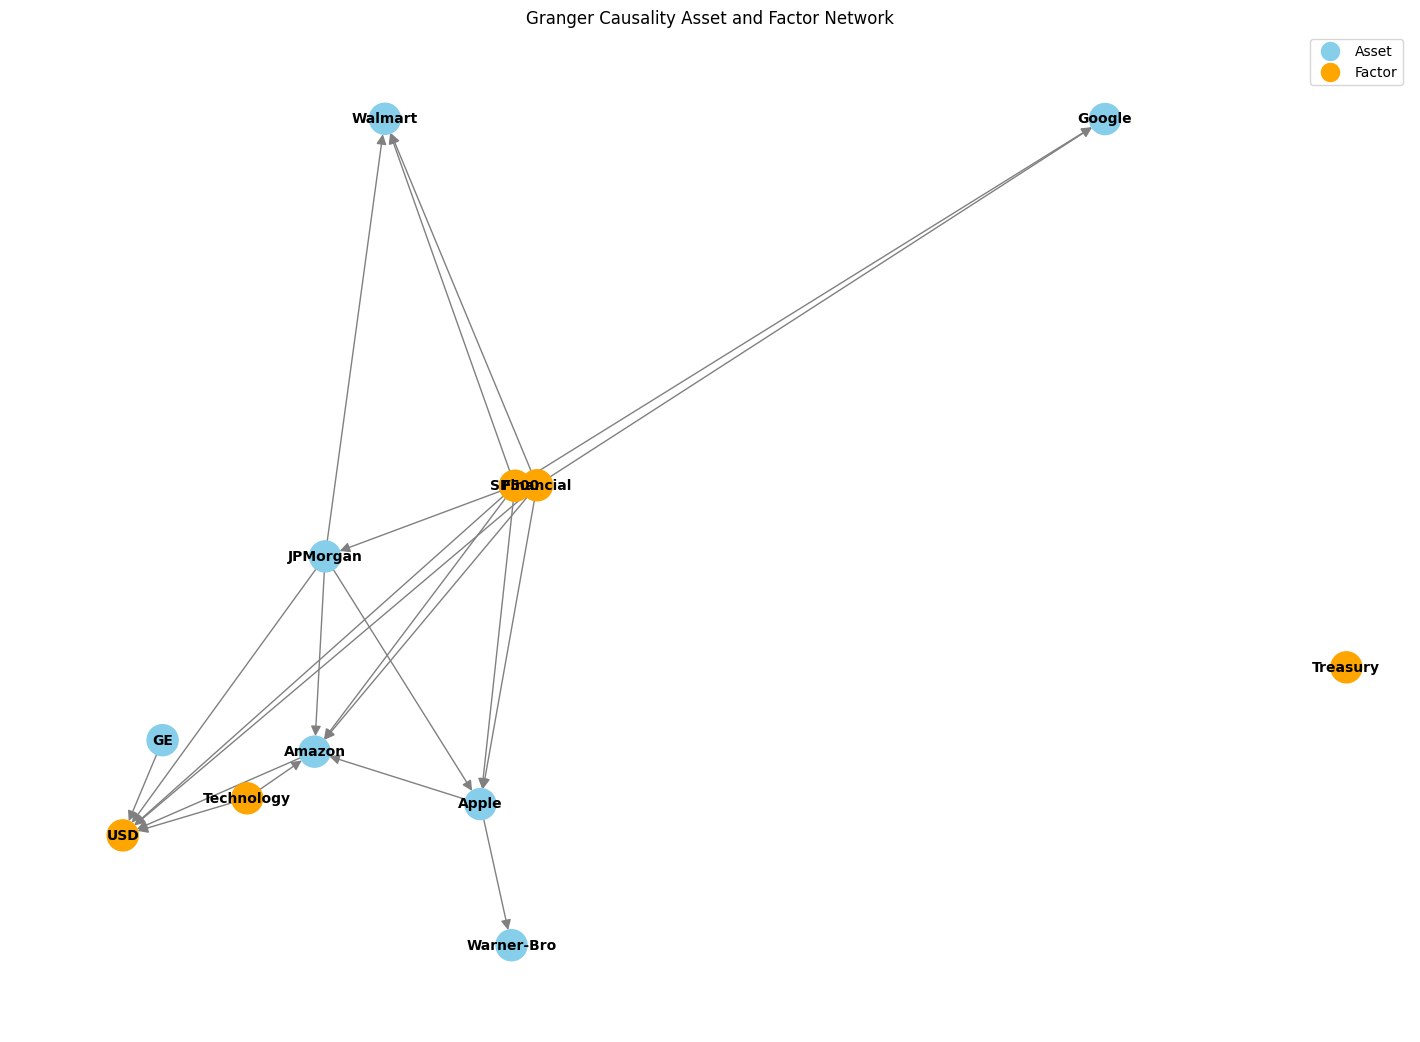

In [13]:
# Tạo và trực quan hóa mạng lưới

# Gán loại cho các nút
node_types = {
    'Apple':'Asset',
    'Amazon':'Asset',
    'USD':'Factor',
    'GE':'Asset',
    'Google':'Asset',
    'JPMorgan':'Asset',
    'Treasury':'Factor',
    'Warner-Bro':'Asset',
    'Walmart':'Asset',
    'Financial':'Factor',
    'Technology':'Factor',
    'SP500':'Factor',
}

nx.set_node_attributes(G, node_types, 'type')

# Vẽ đồ thị mạng lưới
plt.figure(figsize=(14, 10))

# Dùng màu khác nhau cho tài sản và yếu tố
node_colors = ['skyblue' if G.nodes[name]['type'] == 'Asset' else 'orange' for name in G.nodes()]

# Tạo bố cục
pos = nx.spring_layout(G, seed=42)

# Vẽ mạng lưới
nx.draw(G, pos,
        with_labels=True,
        node_size=500,
        node_color=node_colors,
        font_size=10,
        font_weight='bold',
        edge_color='gray',
        arrows=True,
        arrowsize=15)

# Thêm chú giải
asset_patch = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='skyblue',
                       markersize=15, label='Tài sản')
factor_patch = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange',
                        markersize=15, label='Yếu tố')
plt.legend(handles=[asset_patch, factor_patch], loc='upper right')

plt.title('Mạng tài sản-yếu tố theo nhân quả Granger')
plt.show()

Đồ thị mạng ở trên cho một số kết quả kiểm định nhân quả Granger thú vị. Từ đồ thị, ta thấy ETF SP500 và ETF Tài chính Granger gây ra mọi lợi suất cổ phiếu trừ GE và Warner Brothers. Một quan sát thú vị là một số cổ phiếu cũng Granger gây ra ETF USD. Ví dụ, không chỉ SP500 Granger gây ra ETF USD, Amazon cũng Granger gây ra ETF USD. Có thể có một quan hệ giả ở đây. Như đã bàn, kiểm định nhân quả Granger trong mô hình VAR hai biến có thể gặp vấn đề không có biến gây nhiễu. Trong đồ thị trên, ta thấy SP500 Granger gây ra ETF USD. SP500 cũng Granger gây ra Amazon. Rồi Amazon cũng Granger gây ra ETF USD. SP500 có thể là biến gây nhiễu khi ta kiểm định nhân quả Granger giữa Amazon và ETF USD. Hãy kiểm tra bằng cách chạy mô hình VAR 3 biến sau. Như trước, ta tìm bậc độ trễ tối ưu và khớp mô hình. Khi mô hình đã khớp, ta có thể tiến hành kiểm định nhân quả Granger.

In [14]:
# Tạo bộ dữ liệu để chạy mô hình VAR
gc_data = returns[["Amazon","SP500","USD"]]

# Dùng select_order để tìm bậc độ trễ tối ưu
model = VAR(gc_data)
lag_order_results = model.select_order(maxlags=10)
lag_order = lag_order_results.aic # Cũng có thể dùng bic, fpe hoặc hqic
# Khớp mô hình VAR
model_fitted = model.fit(lag_order)

In [15]:
# Kiểm định nhân quả Granger: JPMorgan Granger gây ra Technology; thống kê kiểm định là kiểm định F
test_result = model_fitted.test_causality(caused='USD', causing='Amazon',kind='f')
print(test_result.summary())

Granger causality F-test. H_0: Amazon does not Granger-cause USD. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         1.673          1.882   0.090 (9, 5166)
-----------------------------------------------


Từ kết quả kiểm định nhân quả Granger ở trên, ta thấy giá trị p là 0.09 nên ta không thể bác bỏ $H_0$ và kết quả là Amazon không Granger gây ra ETF USD. Đây là ví dụ cho thấy việc bỏ sót một biến gây nhiễu có thể làm đổi kết quả kiểm định nhân quả Granger. Trong các tiến bộ nghiên cứu gần đây, các nhà nghiên cứu đã đề xuất một số điều chỉnh để xử lý vấn đề không có biến gây nhiễu. Ta sẽ không bàn chúng trong bài này. Ai quan tâm có thể tìm thấy nhiều thông tin trên mạng. 
### **5. Kết luận**
Trong bài này, ta đã học sự khác biệt giữa liên hệ và nhân quả. Sau đó ta giới thiệu nhân quả Granger và đi qua lý thuyết của nó. Ta cũng bàn các giả định và hạn chế của nhân quả Granger. Cuối cùng ta kết hợp nhân quả Granger và lý thuyết mạng lưới để tạo ra một mạng dựa trên nhân quả Granger. Mạng phức tạp này giúp ta hiểu rõ hơn quan hệ nhân quả Granger giữa các tài sản và yếu tố.

### **Tài liệu tham khảo**
1. Nicolae và cộng sự, "Part I: Exploring Data, 10. Data Collection, Causality and Association", Introduction to Data Science, University of Chicago, 2022, https://ds1.datascience.uchicago.edu/10/data-collection.html
2. Hansen "Conditional Expectation and Projection: Causal Effect ", Econometrics, University of Wisconsin, 2014, pp. 43
3. Billio, M., Getmansky, M., Lo, A. W. and L. Pelizzon. (2012) Econometric measures of connectedness and systemic risk in the finance and insurance sectors. Journal of Financial Economics, 104(3), pp. 535–559.